In [11]:
import uuid
from dataclasses import dataclass
import numpy as np
import ufl, basix.ufl
from mpi4py import MPI
from petsc4py import PETSc
from dolfinx import mesh, fem
from dolfinx.fem.petsc import NonlinearProblem
import matplotlib.pyplot as plt

In [12]:
@dataclass
class ElasticaSolution:
    theta: fem.Function   # angle field on V
    fx: float             # horizontal force multiplier
    fy: float             # vertical   force multiplier
    reason: int           # SNES converged reason (>0 = converged)
    iterations: int       # Newton iterations


def solve_elastica(V, R, d, phi1, phi2, theta0=None, fx0=0.0, fy0=0.0, petsc_options=None):
    """Solve the constrained planar elastica on prebuilt function spaces.

    Minimizes  0.5*int(theta'^2)  subject to  int(cos theta) = d  and  int(sin theta) = 0,
    with clamped angles  theta = phi1 at s=0  and  theta = phi2 at s=L
    (the endpoints are read from the mesh extent).

    Parameters
    ----------
    V, R : dolfinx.fem.FunctionSpace
        V : Lagrange space for the angle theta.
        R : real (global-scalar) space -- one dof -- used for each force multiplier.
        Both are built once outside and reused across solves (same mesh assumed).
    d, phi1, phi2 : float
        Constraint values: target end-to-end distance and the two clamped angles.
    theta0 : fem.Function | callable | float, optional
        Initial guess for theta. Pass a previous solution `sol.theta` (a Function on
        the same mesh) to warm-start; a callable x->array or a scalar also work.
        If None (default), a linear phi1->phi2 ramp is used -- a non-flat guess that
        keeps the Jacobian nonsingular. (A flat theta0 == 0 is singular; see docs.)
    fx0, fy0 : float
        Initial guesses for the force multipliers.
    petsc_options : dict, optional
        Overrides/extends the default SNES options.

    Returns
    -------
    ElasticaSolution
        theta (solved Function), fx, fy (floats), SNES reason and iteration count.
        Raises RuntimeError if the solve does not converge.
    """
    domain, comm = V.mesh, V.mesh.comm

    # endpoints of the beam (MPI-safe), needed for the BCs and the default ramp
    xg = domain.geometry.x[:, 0]
    x0 = comm.allreduce(xg.min(), op=MPI.MIN)
    xL = comm.allreduce(xg.max(), op=MPI.MAX)

    # initial guess: a Function (warm start) or callable is interpolated; a scalar fills
    theta, fx, fy = fem.Function(V), fem.Function(R), fem.Function(R)
    if theta0 is None:
        theta0 = lambda x: phi1 + (phi2 - phi1) * (x[0] - x0) / (xL - x0)  # linear ramp
    if np.isscalar(theta0):
        theta.x.array[:] = float(theta0)
    else:
        theta.interpolate(theta0)
    fx.x.array[:] = fx0
    fy.x.array[:] = fy0

    # --- blocked weak form: one residual per test function ---
    v, qx, qy = ufl.TestFunction(V), ufl.TestFunction(R), ufl.TestFunction(R)
    F0 = (ufl.inner(ufl.grad(theta), ufl.grad(v))
          - fx * ufl.sin(theta) * v + fy * ufl.cos(theta) * v) * ufl.dx  # d/dtheta
    F1 = (ufl.cos(theta) - d) * qx * ufl.dx                              # d/dfx
    F2 = ufl.sin(theta) * qy * ufl.dx                                    # d/dfy

    # --- clamped-angle BCs at the mesh endpoints ---
    dofs_l = fem.locate_dofs_geometrical(V, lambda x: np.isclose(x[0], x0))
    dofs_r = fem.locate_dofs_geometrical(V, lambda x: np.isclose(x[0], xL))
    bcs = [fem.dirichletbc(PETSc.ScalarType(phi1), dofs_l, V),
           fem.dirichletbc(PETSc.ScalarType(phi2), dofs_r, V)]

    # --- SNES: Newton LS w/ cubic backtracking; preonly + LU (MUMPS pivots the saddle block) ---
    opts = {"snes_type": "newtonls", "snes_linesearch_type": "bt",
            "snes_linesearch_order": 3, "snes_rtol": 1e-10, "snes_atol": 1e-12,
            "snes_max_it": 100, "ksp_type": "preonly", "pc_type": "lu",
            "pc_factor_mat_solver_type": "mumps"}
    if petsc_options is not None:
        opts.update(petsc_options)

    problem = NonlinearProblem([F0, F1, F2], [theta, fx, fy],
                               petsc_options_prefix=f"elastica_{uuid.uuid4().hex[:8]}_",
                               bcs=bcs, petsc_options=opts)
    problem.solve()
    reason = problem.solver.getConvergedReason()
    if reason <= 0:
        raise RuntimeError(f"SNES did not converge (reason={reason})")
    return ElasticaSolution(theta, float(fx.x.array[0]), float(fy.x.array[0]),
                            int(reason), int(problem.solver.getIterationNumber()))

In [13]:
# --- Build the mesh and function spaces ONCE, outside the solver ---
L, N = 1.0, 100
domain = mesh.create_interval(MPI.COMM_WORLD, N, [0.0, L])
V = fem.functionspace(domain, basix.ufl.element("Lagrange", domain.basix_cell(), 1))  # angle theta
R = fem.functionspace(domain, basix.ufl.real_element(domain.basix_cell()))            # scalar multiplier

# --- Solve for a given set of constraint values; theta0 defaults to the phi1->phi2 ramp ---
d, phi1, phi2 = 0.9, -1, -1
sol = solve_elastica(V, R, d, phi1, phi2)

# --- Post-processing from the returned solution ---
xco = V.tabulate_dof_coordinates()[:, 0]
order = np.argsort(xco)
s = xco[order]

theta_vals = sol.theta.x.array[order]
M_val = (theta_vals[1] - theta_vals[0]) / (s[1] - s[0])               # bending moment theta'(0)
U_val = fem.assemble_scalar(fem.form(0.5 * ufl.inner(ufl.grad(sol.theta),
                                                     ufl.grad(sol.theta)) * ufl.dx))  # energy

print(f"fx = {sol.fx}, fy = {sol.fy}, M = {M_val}, U = {U_val}")
print(f"converged in {sol.iterations} Newton iterations (reason={sol.reason})")

RuntimeError: SNES did not converge (reason=-6)

x(L) = 0.899968  (target d = 0.9)
y(L) = 5.204e-18  (target 0)


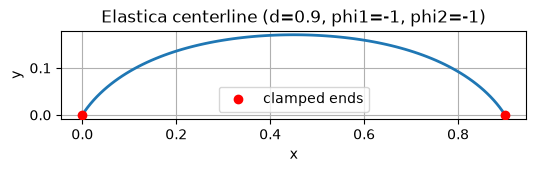

In [14]:
# --- Reconstruct centerline (x(s), y(s)) from the nodal theta values (trapezoid rule) ---
x = np.concatenate(([0.0], np.cumsum(0.5 * (np.cos(theta_vals[:-1]) + np.cos(theta_vals[1:])) * np.diff(s))))
y = np.concatenate(([0.0], np.cumsum(0.5 * (np.sin(theta_vals[:-1]) + np.sin(theta_vals[1:])) * np.diff(s))))

# verify the two constraints were met by the solve
print(f"x(L) = {x[-1]:.6f}  (target d = {d})")
print(f"y(L) = {y[-1]:.3e}  (target 0)")

plt.figure(figsize=(6, 4))
plt.plot(x, y, lw=2)
plt.scatter([x[0], x[-1]], [y[0], y[-1]], color="red", zorder=5, label="clamped ends")
plt.gca().set_aspect("equal")
plt.xlabel("x"); plt.ylabel("y")
plt.title(f"Elastica centerline (d={d}, phi1={phi1}, phi2={phi2})")
plt.legend(); plt.grid(True)
plt.savefig("elastica_shape.png", dpi=150)
plt.show()

In [5]:
# --- Warm-starting: feed one solution in as the initial guess for a nearby problem ---
# `sol` above solved d=0.9. Solve a more-compressed d=0.7 two ways on the SAME spaces:
cold = solve_elastica(V, R, d=0.7, phi1=phi1, phi2=phi2)                    # default ramp guess
warm = solve_elastica(V, R, d=0.7, phi1=phi1, phi2=phi2, theta0=sol.theta)  # guess = d=0.9 solution

print(f"cold start (ramp)      : {cold.iterations} Newton iterations, fx = {cold.fx:.6f}")
print(f"warm start (prev soln) : {warm.iterations} Newton iterations, fx = {warm.fx:.6f}")
assert np.isclose(cold.fx, warm.fx)  # same solution, fewer iterations from the warm start

cold start (ramp)      : 13 Newton iterations, fx = 43.849394
warm start (prev soln) : 5 Newton iterations, fx = 43.849394
